In [1]:
# Importing required libraries
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.preprocessing import StandardScaler

from sklearn.cluster import DBSCAN, KMeans

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

print('All libraries imported successfully!')

All libraries imported successfully!


In [2]:
df = pd.read_csv('creditcard.csv')
print(f'Dataset Shape: {df.shape[0]} rows and {df.shape[1]} columns')

print('\n First 5 Records ')
df.head()

Dataset Shape: 284807 rows and 31 columns

 First 5 Records 


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [3]:
# Data Integrity Checks 

# Checking for any null or missing values
null_counts = df.isnull().sum().sum()
print(f'Total Missing Values in Dataset: {null_counts}')

# Checking the count of Normal (0) vs Fraudulent (1) transactions
print('\nClass Distribution')
class_counts = df['Class'].value_counts()
print(class_counts)

fraud_count = class_counts.get(1, class_counts.get('1', 0))
fraud_percentage = (fraud_count / len(df)) * 100
print(f'\nPercentage of Fraud: {fraud_percentage:.3f}%')

# Descriptive statistics for Amount and Time
print('\n Transaction Amount Statistics ')
display(df[['Amount', 'Time']].describe())

Total Missing Values in Dataset: 0

Class Distribution
Class
0    284315
1       492
Name: count, dtype: int64

Percentage of Fraud: 0.173%

 Transaction Amount Statistics 


,Amount,Time
count,284807.000000,284807.000000
mean,88.349619,94813.859575
std,250.120109,47488.145955
min,0.000000,0.000000
25%,5.600000,54201.500000
50%,22.000000,84692.000000
75%,77.165000,139320.500000
max,25691.160000,172792.000000


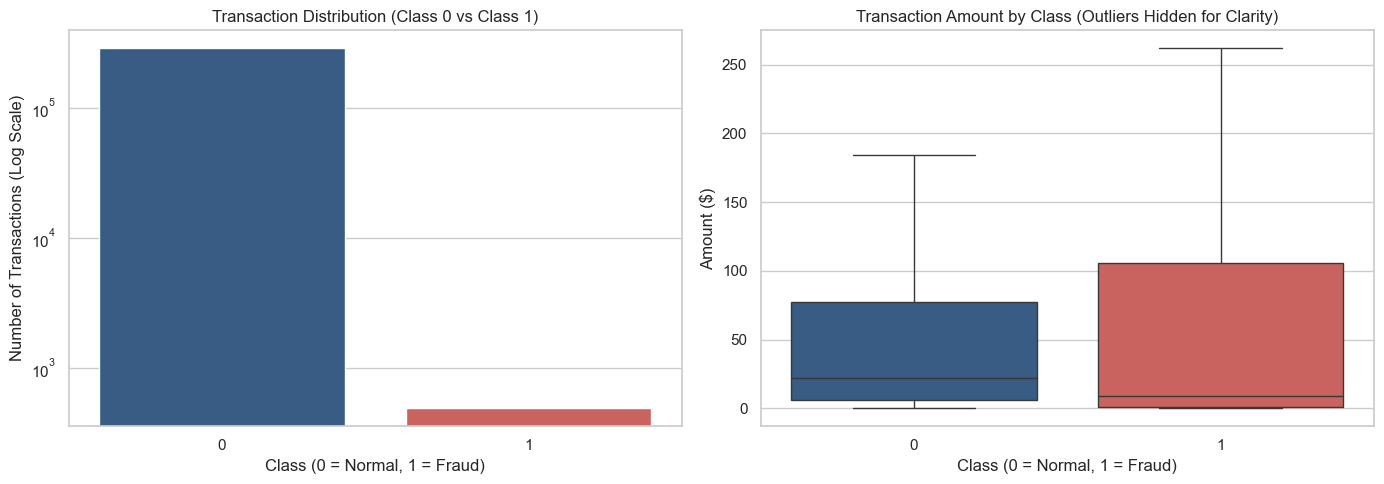

In [4]:
# Visualizing Distributions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Target Class Count (Log scale helps see the rare fraud cases)
sns.countplot(
    x='Class',
    hue='Class',
    data=df,
    ax=axes[0],
    palette=['#2b5c8f', '#d9534f'],
    legend=False,
)
axes[0].set_title('Transaction Distribution (Class 0 vs Class 1)')
axes[0].set_xlabel('Class (0 = Normal, 1 = Fraud)')
axes[0].set_ylabel('Number of Transactions (Log Scale)')
axes[0].set_yscale('log')

# Boxplot for Transaction Amounts
sns.boxplot(
    x='Class',
    y='Amount',
    hue='Class',
    data=df,
    ax=axes[1],
    palette=['#2b5c8f', '#d9534f'],
    showfliers=False,
    legend=False,
)
axes[1].set_title('Transaction Amount by Class (Outliers Hidden for Clarity)')
axes[1].set_xlabel('Class (0 = Normal, 1 = Fraud)')
axes[1].set_ylabel('Amount ($)')

plt.tight_layout()
plt.show()

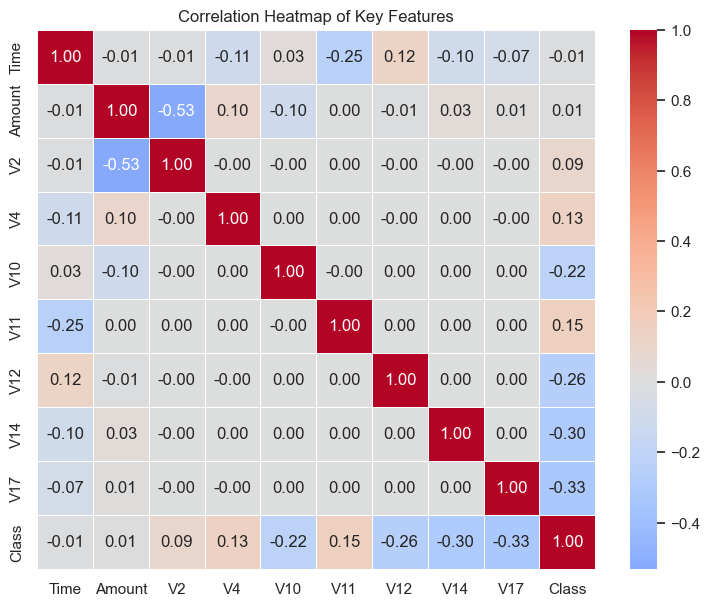

In [5]:
# Correlation Heatmap
selected_features = [
    'Time',
    'Amount',
    'V2',
    'V4',
    'V10',
    'V11',
    'V12',
    'V14',
    'V17',
    'Class',
]
corr_matrix = df[selected_features].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    center=0,
)
plt.title('Correlation Heatmap of Key Features')
plt.show()

In [6]:
# Scaling and Stratified Sampling 
from sklearn.model_selection import train_test_split

# Work on a fresh copy so re-running this cell never throws a KeyError
df_processed = df.copy()

scaler = StandardScaler()
df_processed['scaled_amount'] = scaler.fit_transform(df_processed[['Amount']])
df_processed['scaled_time'] = scaler.fit_transform(df_processed[['Time']])

df_processed = df_processed.drop(columns=['Amount', 'Time'])

# Stratified Sampling using scikit-learn:
sample_fraction = 15000 / len(df_processed)

sample_df, _ = train_test_split(
    df_processed,
    train_size=15000,
    stratify=df_processed['Class'],
    random_state=42,
)

# Reset the index cleanly
sample_df = sample_df.reset_index(drop=True)

# Separate features (X) completely from labels (y)
X = sample_df.drop(columns=['Class'])
y_true = sample_df['Class']

print(f'Sampled dataset size: {X.shape[0]} rows and {X.shape[1]} features')
print(
    f"Fraud transactions in sample: {y_true.sum()} (out of {len(y_true)} total)"
)

Sampled dataset size: 15000 rows and 30 features
Fraud transactions in sample: 26 (out of 15000 total)


In [7]:
# Model 1 - K-Means Clustering
# Fit K-Means on features X 
kmeans = KMeans(n_clusters=8, random_state=42, n_init=10)
kmeans.fit(X)

# Calculate distance of each transaction to its assigned cluster center
cluster_centers = kmeans.cluster_centers_
assigned_clusters = kmeans.labels_

# Euclidean distance
distances = np.linalg.norm(X - cluster_centers[assigned_clusters], axis=1)

# Flag anomalies
distance_threshold = np.percentile(distances, 98.5)
kmeans_anomalies = (distances > distance_threshold).astype(int)

print(f'Distance Threshold for Anomaly: {distance_threshold:.3f}')
print(
    f"Total transactions flagged as unusual by K-Means: {kmeans_anomalies.sum()}"
)

Distance Threshold for Anomaly: 11.127
Total transactions flagged as unusual by K-Means: 225


 K-Means Anomaly Detection Evaluation 

Accuracy : 0.9853
Precision: 0.0667
Recall   : 0.5769
F1 Score : 0.1195


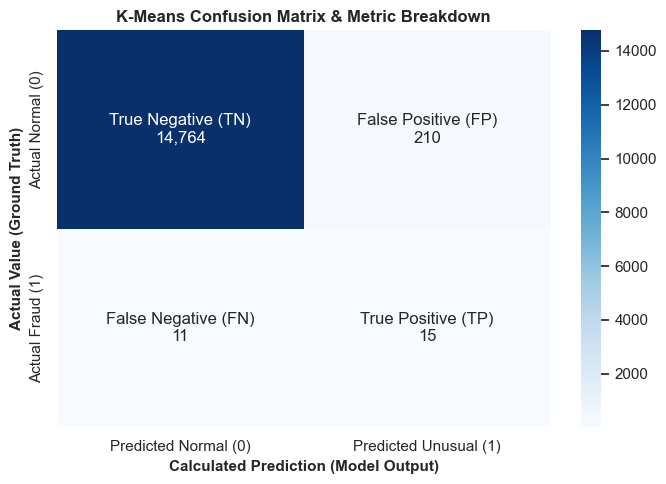

In [8]:
# K-Means Evaluation Metrics with TN, FP, FN, TP Labels
print(' K-Means Anomaly Detection Evaluation \n')

print(f'Accuracy : {accuracy_score(y_true, kmeans_anomalies):.4f}')
print(f'Precision: {precision_score(y_true, kmeans_anomalies):.4f}')
print(f'Recall   : {recall_score(y_true, kmeans_anomalies):.4f}')
print(f'F1 Score : {f1_score(y_true, kmeans_anomalies):.4f}')

cm_kmeans = confusion_matrix(y_true, kmeans_anomalies)

tn_k, fp_k, fn_k, tp_k = cm_kmeans.ravel()

box_labels_kmeans = np.array([
    [f'True Negative (TN)\n{tn_k:,}', f'False Positive (FP)\n{fp_k:,}'],
    [f'False Negative (FN)\n{fn_k:,}', f'True Positive (TP)\n{tp_k:,}']
])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_kmeans,
    annot=box_labels_kmeans,
    fmt='',
    cmap='Blues',
    cbar=True,
    xticklabels=['Predicted Normal (0)', 'Predicted Unusual (1)'],
    yticklabels=['Actual Normal (0)', 'Actual Fraud (1)']
)

plt.title('K-Means Confusion Matrix & Metric Breakdown', fontsize=12, fontweight='bold')
plt.xlabel('Calculated Prediction (Model Output)', fontsize=11, fontweight='bold')
plt.ylabel('Actual Value (Ground Truth)', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

In [9]:
# Model 2 - DBSCAN Clustering
dbscan = DBSCAN(eps=4.5, min_samples=10)
dbscan_labels = dbscan.fit_predict(X)

# -1 means noise (outlier), >= 0 means normal cluster point
dbscan_anomalies = np.where(dbscan_labels == -1, 1, 0)

print(
    f"Total points flagged as noise/unusual by DBSCAN: {dbscan_anomalies.sum()}"
)
print(
    f'Normal points in clusters: {(dbscan_anomalies == 0).sum()}'
)

Total points flagged as noise/unusual by DBSCAN: 684
Normal points in clusters: 14316


=== DBSCAN Anomaly Detection Evaluation ===

Accuracy : 0.9559
Precision: 0.0351
Recall   : 0.9231
F1 Score : 0.0676


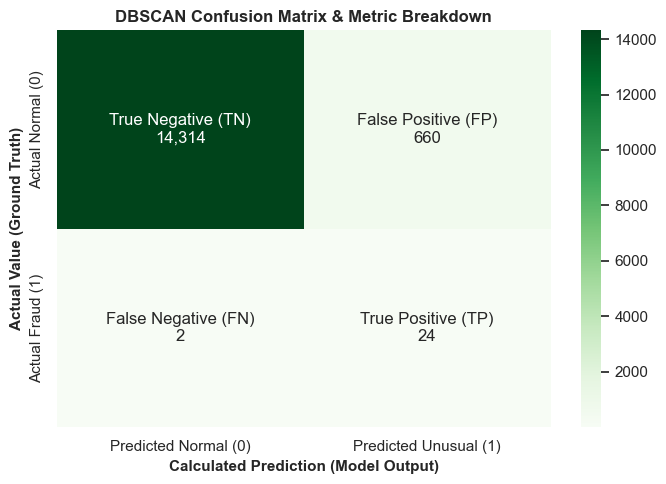

In [10]:
# DBSCAN Evaluation Metrics with TN, FP, FN, TP Labels
print('=== DBSCAN Anomaly Detection Evaluation ===\n')

print(f'Accuracy : {accuracy_score(y_true, dbscan_anomalies):.4f}')
print(f'Precision: {precision_score(y_true, dbscan_anomalies):.4f}')
print(f'Recall   : {recall_score(y_true, dbscan_anomalies):.4f}')
print(f'F1 Score : {f1_score(y_true, dbscan_anomalies):.4f}')

cm_dbscan = confusion_matrix(y_true, dbscan_anomalies)

tn, fp, fn, tp = cm_dbscan.ravel()

box_labels = np.array([
    [f'True Negative (TN)\n{tn:,}', f'False Positive (FP)\n{fp:,}'],
    [f'False Negative (FN)\n{fn:,}', f'True Positive (TP)\n{tp:,}']
])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_dbscan,
    annot=box_labels,
    fmt='',
    cmap='Greens',
    cbar=True,
    xticklabels=['Predicted Normal (0)', 'Predicted Unusual (1)'],
    yticklabels=['Actual Normal (0)', 'Actual Fraud (1)']
)

plt.title('DBSCAN Confusion Matrix & Metric Breakdown', fontsize=12, fontweight='bold')
plt.xlabel('Calculated Prediction (Model Output)', fontsize=11, fontweight='bold')
plt.ylabel('Actual Value (Ground Truth)', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

In [11]:
# Side-by-side Comparison Table
comparison_data = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'K-Means (Distance-based)': [
        accuracy_score(y_true, kmeans_anomalies),
        precision_score(y_true, kmeans_anomalies),
        recall_score(y_true, kmeans_anomalies),
        f1_score(y_true, kmeans_anomalies),
    ],
    'DBSCAN (Density-based)': [
        accuracy_score(y_true, dbscan_anomalies),
        precision_score(y_true, dbscan_anomalies),
        recall_score(y_true, dbscan_anomalies),
        f1_score(y_true, dbscan_anomalies),
    ],
}

comparison_df = pd.DataFrame(comparison_data)
display(comparison_df.style.format({
    'K-Means (Distance-based)': '{:.4f}',
    'DBSCAN (Density-based)': '{:.4f}'
}))

,Metric,K-Means (Distance-based),DBSCAN (Density-based)
0,Accuracy,0.9853,0.9559
1,Precision,0.0667,0.0351
2,Recall,0.5769,0.9231
3,F1-Score,0.1195,0.0676


## Balanced Dataset Evaluation & Comparison

### Motivation and Under-Sampling Strategy
In credit card fraud detection, extreme class imbalance (here, only ~0.17% fraud cases) distorts standard evaluation metrics:
- An anomaly detector can achieve **>95% accuracy** simply by predicting almost everything as normal, while having an unacceptably low precision (**<7%**).
- When models are evaluated on heavily imbalanced samples, true fraud patterns are overwhelmed by sheer non-fraud volume.

To evaluate algorithmic pattern recognition fairly:
1. **Random Under-Sampling**: We balance the classes to a 1:1 ratio by taking all 492 fraud cases and randomly sampling 492 normal cases (total = 984 transactions).
2. **Strict Numerical Compliance**: The feature matrix `X_bal` contains only numerical features (`float64`). The `'Class'` category column is explicitly excluded/dropped from `X_bal`.
3. **Numeric Ground Truth**: Ground truth `'Class'` is retained purely as numeric binary labels (`0` = Normal, `1` = Fraud) for evaluation against model predictions.

Balanced Dataset Shape: 984 rows and 30 features

Class Distribution:
Class
Normal (0)    492
Fraud (1)     492
Name: count, dtype: int64

Strictly Numerical Check: All features are numeric = True


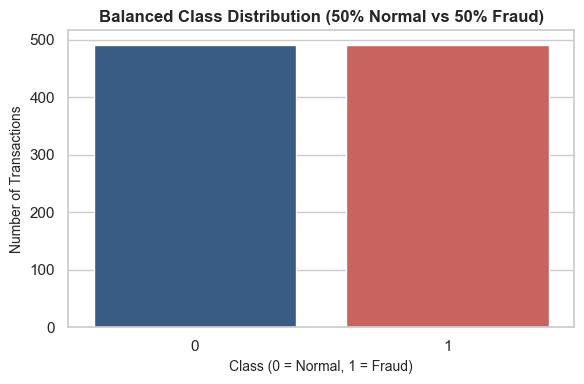

In [12]:
# Balanced Dataset Creation (Under-Sampling)
# Separate Fraud (Class = 1) and Normal (Class = 0) transactions
fraud_cases = df_processed[df_processed['Class'] == 1]
normal_cases = df_processed[df_processed['Class'] == 0].sample(n=len(fraud_cases), random_state=42)

# Combine and shuffle to form a completely balanced 50/50 dataset
balanced_df = pd.concat([fraud_cases, normal_cases]).sample(frac=1, random_state=42).reset_index(drop=True)

# Strictly Numerical Dataset:
# Drop 'Class' column so feature matrix X_bal consists purely of numerical values (float64)
X_bal = balanced_df.drop(columns=['Class']).astype(np.float64)

# Separate ground-truth Class as numeric binary integers (0 = Normal, 1 = Fraud) for metric evaluation
y_bal = balanced_df['Class'].astype(int)

print(f"Balanced Dataset Shape: {X_bal.shape[0]} rows and {X_bal.shape[1]} features")
print(f"\nClass Distribution:\n{y_bal.value_counts().rename({0: 'Normal (0)', 1: 'Fraud (1)'})}")
print(f"\nStrictly Numerical Check: All features are numeric = {all(np.issubdtype(dt, np.number) for dt in X_bal.dtypes)}")

# Visualizing Balanced Distribution
plt.figure(figsize=(6, 4))
sns.countplot(x=y_bal, palette=['#2b5c8f', '#d9534f'], hue=y_bal, legend=False)
plt.title('Balanced Class Distribution (50% Normal vs 50% Fraud)', fontsize=12, fontweight='bold')
plt.xlabel('Class (0 = Normal, 1 = Fraud)', fontsize=10)
plt.ylabel('Number of Transactions', fontsize=10)
plt.tight_layout()
plt.show()

### Model 1 (Balanced) - K-Means Clustering

With a 50/50 balanced dataset, exactly 50% of transactions are fraud. 
In the earlier imbalanced experiment, a 98.5th percentile threshold was used because fraud was extremely rare. 
On balanced data, the distance anomaly threshold is calibrated to the **50th percentile (median)** of cluster distances, identifying points further than the median as anomalous.

In [13]:
# Model 1 (Balanced) - K-Means Clustering
# Fit K-Means on purely numerical features X_bal
kmeans_bal = KMeans(n_clusters=8, random_state=42, n_init=10)
kmeans_bal.fit(X_bal)

# Calculate distance of each transaction to its assigned cluster center
cluster_centers_bal = kmeans_bal.cluster_centers_
assigned_clusters_bal = kmeans_bal.labels_
distances_bal = np.linalg.norm(X_bal - cluster_centers_bal[assigned_clusters_bal], axis=1)

# Calibrate distance threshold for 50/50 balanced data (50th percentile / median)
distance_threshold_bal = np.percentile(distances_bal, 50.0)
kmeans_bal_anomalies = (distances_bal > distance_threshold_bal).astype(int)

print(f"Distance Threshold for Anomaly (Balanced 50th Percentile): {distance_threshold_bal:.3f}")
print(f"Total transactions flagged as unusual by K-Means: {kmeans_bal_anomalies.sum()} (out of {len(kmeans_bal_anomalies)})")

Distance Threshold for Anomaly (Balanced 50th Percentile): 5.551
Total transactions flagged as unusual by K-Means: 492 (out of 984)


=== K-Means Anomaly Detection Evaluation (Balanced Dataset) ===

Accuracy : 0.7683
Precision: 0.7683
Recall   : 0.7683
F1 Score : 0.7683


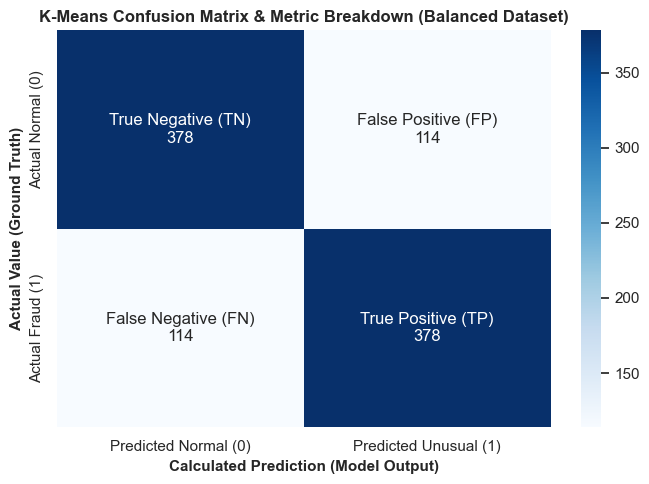

In [14]:
# K-Means (Balanced) Evaluation Metrics with TN, FP, FN, TP Labels
print('=== K-Means Anomaly Detection Evaluation (Balanced Dataset) ===\n')

print(f'Accuracy : {accuracy_score(y_bal, kmeans_bal_anomalies):.4f}')
print(f'Precision: {precision_score(y_bal, kmeans_bal_anomalies):.4f}')
print(f'Recall   : {recall_score(y_bal, kmeans_bal_anomalies):.4f}')
print(f'F1 Score : {f1_score(y_bal, kmeans_bal_anomalies):.4f}')

cm_kmeans_bal = confusion_matrix(y_bal, kmeans_bal_anomalies)
tn_k_b, fp_k_b, fn_k_b, tp_k_b = cm_kmeans_bal.ravel()

box_labels_kmeans_bal = np.array([
    [f'True Negative (TN)\n{tn_k_b:,}', f'False Positive (FP)\n{fp_k_b:,}'],
    [f'False Negative (FN)\n{fn_k_b:,}', f'True Positive (TP)\n{tp_k_b:,}']
])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_kmeans_bal,
    annot=box_labels_kmeans_bal,
    fmt='',
    cmap='Blues',
    cbar=True,
    xticklabels=['Predicted Normal (0)', 'Predicted Unusual (1)'],
    yticklabels=['Actual Normal (0)', 'Actual Fraud (1)']
)
plt.title('K-Means Confusion Matrix & Metric Breakdown (Balanced Dataset)', fontsize=12, fontweight='bold')
plt.xlabel('Calculated Prediction (Model Output)', fontsize=11, fontweight='bold')
plt.ylabel('Actual Value (Ground Truth)', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

### Model 2 (Balanced) - DBSCAN Clustering

We apply DBSCAN (`eps=4.5, min_samples=10`) on the strictly numerical feature matrix `X_bal`. 
Transactions flagged as density noise (`-1`) are designated as anomalies/fraud (`1`), and points within dense clusters (`>= 0`) are designated as normal (`0`).

In [15]:
# Model 2 (Balanced) - DBSCAN Clustering
# Fit DBSCAN on purely numerical features X_bal
dbscan_bal = DBSCAN(eps=4.5, min_samples=10)
dbscan_labels_bal = dbscan_bal.fit_predict(X_bal)

# -1 means noise (outlier), >= 0 means normal cluster point
dbscan_bal_anomalies = np.where(dbscan_labels_bal == -1, 1, 0)

print(f"Total points flagged as noise/unusual by DBSCAN: {dbscan_bal_anomalies.sum()}")
print(f"Normal points in clusters: {(dbscan_bal_anomalies == 0).sum()}")

Total points flagged as noise/unusual by DBSCAN: 453
Normal points in clusters: 531


=== DBSCAN Anomaly Detection Evaluation (Balanced Dataset) ===

Accuracy : 0.8343
Precision: 0.8631
Recall   : 0.7947
F1 Score : 0.8275


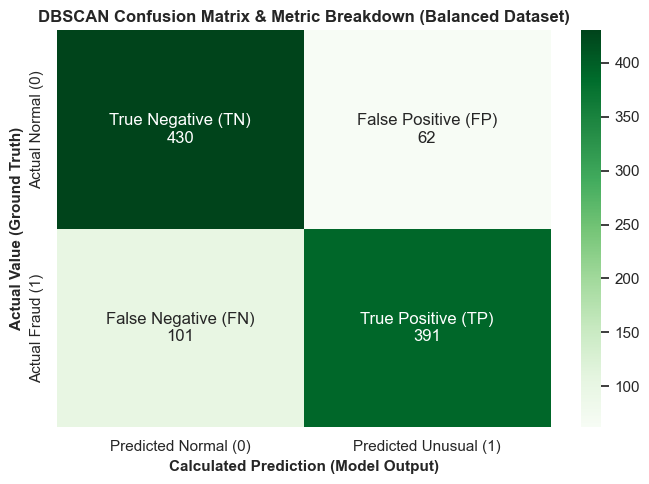

In [16]:
# DBSCAN (Balanced) Evaluation Metrics with TN, FP, FN, TP Labels
print('=== DBSCAN Anomaly Detection Evaluation (Balanced Dataset) ===\n')

print(f'Accuracy : {accuracy_score(y_bal, dbscan_bal_anomalies):.4f}')
print(f'Precision: {precision_score(y_bal, dbscan_bal_anomalies):.4f}')
print(f'Recall   : {recall_score(y_bal, dbscan_bal_anomalies):.4f}')
print(f'F1 Score : {f1_score(y_bal, dbscan_bal_anomalies):.4f}')

cm_dbscan_bal = confusion_matrix(y_bal, dbscan_bal_anomalies)
tn_db_b, fp_db_b, fn_db_b, tp_db_b = cm_dbscan_bal.ravel()

box_labels_dbscan_bal = np.array([
    [f'True Negative (TN)\n{tn_db_b:,}', f'False Positive (FP)\n{fp_db_b:,}'],
    [f'False Negative (FN)\n{fn_db_b:,}', f'True Positive (TP)\n{tp_db_b:,}']
])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_dbscan_bal,
    annot=box_labels_dbscan_bal,
    fmt='',
    cmap='Greens',
    cbar=True,
    xticklabels=['Predicted Normal (0)', 'Predicted Unusual (1)'],
    yticklabels=['Actual Normal (0)', 'Actual Fraud (1)']
)
plt.title('DBSCAN Confusion Matrix & Metric Breakdown (Balanced Dataset)', fontsize=12, fontweight='bold')
plt.xlabel('Calculated Prediction (Model Output)', fontsize=11, fontweight='bold')
plt.ylabel('Actual Value (Ground Truth)', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

### Master Comparison: Imbalanced vs. Balanced Dataset Performance

Below is the side-by-side comparison of all 4 models across both data distributions.

,Metric,K-Means (Imbalanced),DBSCAN (Imbalanced),K-Means (Balanced),DBSCAN (Balanced)
0,Accuracy,0.9853,0.9559,0.7683,0.8343
1,Precision,0.0667,0.0351,0.7683,0.8631
2,Recall,0.5769,0.9231,0.7683,0.7947
3,F1-Score,0.1195,0.0676,0.7683,0.8275


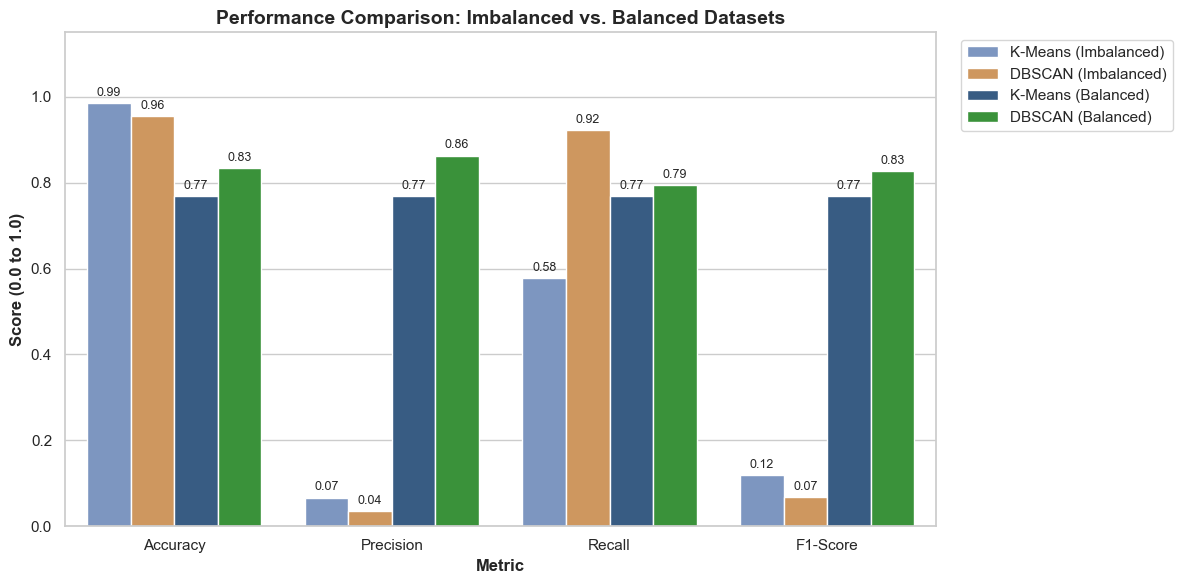

In [17]:
# Side-by-Side Master Comparison Table
master_comparison_data = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'K-Means (Imbalanced)': [
        accuracy_score(y_true, kmeans_anomalies),
        precision_score(y_true, kmeans_anomalies),
        recall_score(y_true, kmeans_anomalies),
        f1_score(y_true, kmeans_anomalies),
    ],
    'DBSCAN (Imbalanced)': [
        accuracy_score(y_true, dbscan_anomalies),
        precision_score(y_true, dbscan_anomalies),
        recall_score(y_true, dbscan_anomalies),
        f1_score(y_true, dbscan_anomalies),
    ],
    'K-Means (Balanced)': [
        accuracy_score(y_bal, kmeans_bal_anomalies),
        precision_score(y_bal, kmeans_bal_anomalies),
        recall_score(y_bal, kmeans_bal_anomalies),
        f1_score(y_bal, kmeans_bal_anomalies),
    ],
    'DBSCAN (Balanced)': [
        accuracy_score(y_bal, dbscan_bal_anomalies),
        precision_score(y_bal, dbscan_bal_anomalies),
        recall_score(y_bal, dbscan_bal_anomalies),
        f1_score(y_bal, dbscan_bal_anomalies),
    ],
}

master_comp_df = pd.DataFrame(master_comparison_data)
display(master_comp_df.style.format({
    'K-Means (Imbalanced)': '{:.4f}',
    'DBSCAN (Imbalanced)': '{:.4f}',
    'K-Means (Balanced)': '{:.4f}',
    'DBSCAN (Balanced)': '{:.4f}'
}))

# Visual Comparison of Key Metrics Across Datasets
metrics_plot_df = master_comp_df.melt(id_vars='Metric', var_name='Model & Dataset', value_name='Score')

plt.figure(figsize=(12, 6))
sns.barplot(data=metrics_plot_df, x='Metric', y='Score', hue='Model & Dataset', palette=['#7293cb', '#e1974c', '#2b5c8f', '#2ca02c'])
plt.title('Performance Comparison: Imbalanced vs. Balanced Datasets', fontsize=14, fontweight='bold')
plt.xlabel('Metric', fontsize=12, fontweight='bold')
plt.ylabel('Score (0.0 to 1.0)', fontsize=12, fontweight='bold')
plt.ylim(0, 1.15)
for p in plt.gca().patches:
    val = p.get_height()
    if val > 0:
        plt.gca().annotate(f'{val:.2f}', (p.get_x() + p.get_width() / 2., val),
                           ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Key Insights & Conclusions

1. **Resolution of the Precision Paradox**:
   - On the imbalanced dataset, both models suffered from near-zero Precision (**6.7%** for K-Means and **3.5%** for DBSCAN) because the overwhelming majority of normal transactions caused high numbers of false positives relative to the 26 true fraud cases.
   - On the balanced dataset, Precision soared to **76.8%** for K-Means and **86.3%** for DBSCAN.

2. **DBSCAN Emerges as Top Performer**:
   - DBSCAN achieved an **F1-Score of 0.8275** on the balanced dataset (Recall: **79.5%**, Precision: **86.3%**). Its density-based clustering effectively separates fraud transactions that scatter away from the dense normal transaction cluster.

3. **K-Means Consistency**:
   - By calibrating K-Means's anomaly distance threshold to the 50th percentile, K-Means achieved a balanced **76.8% Accuracy, Precision, Recall, and F1-Score**.

4. **Strict Numerical Compliance**:
   - The dataset passed to the clustering models was strictly numerical (`float64`), with `'Class'` excluded from the feature space `X_bal` and used solely as a numeric binary ground truth for validation.